# Does sharpness-aware minimisation (SAM) improve calibration over SGD on Fashion-MNIST?

This notebook demonstrates the artifact `method.py`. It trains a small two-block CNN on Fashion-MNIST with plain SGD (momentum 0.9) and with SAM on the same base optimiser, using the same architecture, data split, batch order and per-seed initialisation. It then compares accuracy, ECE, NLL, Brier and AURC on the test set, and checks whether SAM's calibration advantage survives temperature scaling of the SGD model.

**Demo scope.** The notebook runs on a 100-image, class-balanced subset of Fashion-MNIST (`mini_demo_data.json`: 60 train, 20 validation, 20 test) so that it finishes in minutes. The numbers it prints are therefore not the paper's results: the paper trains on 50,000 images and evaluates on the official 10,000-image test set. The config cell sets the scale.

**Selected hyperparameters.** The learning rates (SGD 0.01, SAM 0.01) and SAM's rho (0.1) are the values the original pipeline selected on validation NLL with seed 100. The demo uses them directly and skips the tuning grid.

## Install dependencies
Install the packages the notebook imports. On Colab the core scientific packages are already installed and must not be reinstalled, so they are only installed locally.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Not pre-installed on Colab: always install
_pip('loguru==0.8.0')

# Core packages (pre-installed on Colab, install locally to match Colab env)
if 'google.colab' not in sys.modules:
    # torch is not pinned here: this machine's pip constraint file fixes its own torch build.
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'torch')


## Imports
The original import block (without the torchvision and `metrics` imports, which are replaced by the JSON loader and the in-notebook metrics below), followed by the shared figure style.

In [2]:
from __future__ import annotations

import gc
import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from loguru import logger

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Metric functions
The calibration and accuracy metrics from `metrics.py`, the module the original script imports as `M`. They are defined here so the notebook needs no extra file; calls use the bare names instead of `M.`.

In [3]:
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp

N_BINS = 15
TEMP_LO, TEMP_HI = 0.05, 20.0


def softmax64(logits: np.ndarray) -> np.ndarray:
    z = logits.astype(np.float64)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def nll_per_example(logits: np.ndarray, labels: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    z = logits.astype(np.float64) / temperature
    lse = logsumexp(z, axis=1)
    return lse - z[np.arange(len(z)), labels]


def confidence_and_correct(logits: np.ndarray, labels: np.ndarray, temperature: float = 1.0):
    probs = softmax64(logits / temperature)
    conf = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == labels).astype(np.float64)
    return conf, correct, probs


def brier_per_example(probs: np.ndarray, labels: np.ndarray) -> np.ndarray:
    onehot = np.eye(probs.shape[1])[labels]
    return np.sum((probs - onehot) ** 2, axis=1)


def ece(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> float:
    """Expected calibration error with equal-width bins over (0, 1]."""
    n = len(conf)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.searchsorted(edges, conf, side="left") - 1, 0, n_bins - 1)
    cnt = np.bincount(idx, minlength=n_bins).astype(np.float64)
    sum_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    sum_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    nz = cnt > 0
    return float(np.abs(sum_acc[nz] - sum_conf[nz]).sum() / n)


def reliability_bins(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> dict:
    """Per-bin counts, mean confidence and accuracy (equal-width bins)."""
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.searchsorted(edges, conf, side="left") - 1, 0, n_bins - 1)
    cnt = np.bincount(idx, minlength=n_bins)
    sum_conf = np.bincount(idx, weights=conf, minlength=n_bins)
    sum_acc = np.bincount(idx, weights=correct, minlength=n_bins)
    with np.errstate(invalid="ignore", divide="ignore"):
        mean_conf = np.where(cnt > 0, sum_conf / np.maximum(cnt, 1), np.nan)
        acc = np.where(cnt > 0, sum_acc / np.maximum(cnt, 1), np.nan)
    return {
        "edges": edges.tolist(),
        "count": cnt.tolist(),
        "mean_confidence": mean_conf.tolist(),
        "accuracy": acc.tolist(),
    }


def ace(conf: np.ndarray, correct: np.ndarray, n_bins: int = N_BINS) -> float:
    """Adaptive calibration error: equal-mass bins, unweighted mean over bins."""
    order = np.argsort(conf, kind="stable")
    groups = np.array_split(order, n_bins)
    vals = [abs(correct[g].mean() - conf[g].mean()) for g in groups if len(g) > 0]
    return float(np.mean(vals))


def aurc(conf: np.ndarray, correct: np.ndarray) -> float:
    """Area under the risk-coverage curve (ranking by confidence, descending)."""
    order = np.argsort(-conf, kind="stable")
    err = (1.0 - correct)[order]
    cum = np.cumsum(err)
    risk = cum / np.arange(1, len(err) + 1)
    return float(risk.mean())


def all_metrics(logits: np.ndarray, labels: np.ndarray, temperature: float = 1.0) -> dict:
    conf, correct, probs = confidence_and_correct(logits, labels, temperature)
    return {
        "accuracy": float(correct.mean()),
        "ece": ece(conf, correct),
        "ace": ace(conf, correct),
        "nll": float(nll_per_example(logits, labels, temperature).mean()),
        "brier": float(brier_per_example(probs, labels).mean()),
        "aurc": aurc(conf, correct),
    }


def bootstrap_ci(logits: np.ndarray, labels: np.ndarray, temperature: float = 1.0,
                 n_boot: int = 1000, seed: int = 0) -> dict:
    """95% percentile bootstrap CI over test examples, one resample per replicate."""
    conf, correct, probs = confidence_and_correct(logits, labels, temperature)
    nll_pe = nll_per_example(logits, labels, temperature)
    brier_pe = brier_per_example(probs, labels)
    rng = np.random.default_rng(seed)
    n = len(labels)
    samples = {k: np.empty(n_boot) for k in ("accuracy", "ece", "ace", "nll", "brier", "aurc")}
    for b in range(n_boot):
        i = rng.integers(0, n, size=n)
        c, r = conf[i], correct[i]
        samples["accuracy"][b] = r.mean()
        samples["ece"][b] = ece(c, r)
        samples["ace"][b] = ace(c, r)
        samples["nll"][b] = nll_pe[i].mean()
        samples["brier"][b] = brier_pe[i].mean()
        samples["aurc"][b] = aurc(c, r)
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]
            for k, v in samples.items()}


def fit_temperature(logits: np.ndarray, labels: np.ndarray) -> dict:
    """Fit one temperature on validation logits by minimising validation NLL.

    Bounded scalar minimisation over [0.05, 20]. A coarse log-grid is also
    evaluated so that a non-global bounded-search optimum is visible.
    """
    def obj(t: float) -> float:
        return float(nll_per_example(logits, labels, t).mean())

    res = minimize_scalar(obj, bounds=(TEMP_LO, TEMP_HI), method="bounded",
                          options={"xatol": 1e-6})
    grid = np.exp(np.linspace(np.log(TEMP_LO), np.log(TEMP_HI), 400))
    grid_vals = np.array([obj(t) for t in grid])
    best_grid = float(grid[np.argmin(grid_vals)])
    t_hat = float(res.x)
    at_bound = bool(t_hat <= TEMP_LO * 1.001 or t_hat >= TEMP_HI * 0.999)
    return {
        "temperature": t_hat,
        "val_nll_at_T": obj(t_hat),
        "val_nll_at_bounds": {str(TEMP_LO): obj(TEMP_LO), str(TEMP_HI): obj(TEMP_HI)},
        "grid_best_T": best_grid,
        "grid_best_val_nll": float(grid_vals.min()),
        "at_bound": at_bound,
    }


# ---------------------------------------------------------------- statistics

def paired_t_interval(d: np.ndarray, alpha: float = 0.05) -> dict:
    """Mean of paired differences with a t-interval (df = n - 1) and two-sided p."""
    from scipy import stats

    d = np.asarray(d, dtype=np.float64)
    n = len(d)
    mean = float(d.mean())
    sd = float(d.std(ddof=1)) if n > 1 else 0.0
    se = sd / np.sqrt(n)
    tcrit = float(stats.t.ppf(1 - alpha / 2, n - 1))
    if se == 0.0:
        p = 1.0 if mean == 0.0 else 0.0
        t_stat = float("inf") if mean != 0.0 else 0.0
    else:
        t_stat = mean / se
        p = float(2 * stats.t.sf(abs(t_stat), n - 1))
    return {
        "n": n,
        "df": n - 1,
        "mean": mean,
        "sd": sd,
        "ci95": [mean - tcrit * se, mean + tcrit * se],
        "t": float(t_stat),
        "p": p,
    }


def holm(pvals: dict[str, float]) -> dict[str, float]:
    """Holm step-down adjusted p-values over a family."""
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    adj: dict[str, float] = {}
    running = 0.0
    for rank, (name, p) in enumerate(items):
        val = min(1.0, (m - rank) * p)
        running = max(running, val)
        adj[name] = running
    return adj


# ---------------------------------------------------------------- self-test helpers

def ece_known_example() -> float:
    """Hand-built case with known ECE = 0.1.

    Four examples at confidence 0.9 with 3 correct: bin accuracy 0.75, gap 0.15,
    weight 4/6, contribution 0.1. Two examples at confidence 0.5 with 1 correct:
    bin accuracy 0.5 equals confidence, gap 0. Total ECE = 0.1.
    """
    conf = np.array([0.9, 0.9, 0.9, 0.9, 0.5, 0.5])
    correct = np.array([1, 1, 1, 0, 1, 0], dtype=np.float64)
    return ece(conf, correct)


## Load the data
`data` is the curated 100-image subset. `load_data()` reads it from GitHub and falls back to the local `mini_demo_data.json`.

In [4]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-d46016-sharpness-aware-training-makes-small/main/round-1/experiment-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()
print({k: len(v["y"]) for k, v in data.items() if k != "metadata"}, "examples per split")


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
{'train': 60, 'val': 20, 'test': 20} examples per split


## Config
All tunable values. The first run uses the smallest values (2 epochs, one seed); they are increased in later rounds, see the scaling note at the end.

In [5]:
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
BATCH = 128
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
EPOCHS = 40           # original: 40 (paper setting); first test run used 2
SEEDS = (0, 1, 2, 3, 4)  # original: (0, 1, 2, 3, 4); first test run used (0,)
LR_SGD = 0.01         # selected on validation NLL (seed 100) in the original tuning sweep
LR_SAM = 0.01         # selected on validation NLL (seed 100) in the original tuning sweep
RHO = 0.1             # SAM neighbourhood radius, selected on validation NLL
RESULTS = Path("results")
RUNS = RESULTS / "runs"
LOGS = RESULTS / "logs"
CKPTS = RESULTS / "checkpoints"
LOGS.mkdir(parents=True, exist_ok=True)


## Prepare the data
Convert the lists to tensors and normalise with the training-split mean and standard deviation, as the original `load_data()` did.

In [6]:
def prepare_data(raw: dict) -> dict:
    """Turn the JSON lists into tensors, normalised with train-split statistics.

    Replaces the original load_data(), which downloaded Fashion-MNIST: the subset
    is already split (train/val/test) and stored as integer pixels 0-255.
    """
    def to_tensors(split: str):
        x = torch.tensor(raw[split]["x"], dtype=torch.float32).div(255.0).view(-1, 1, 28, 28)
        y = torch.tensor(raw[split]["y"], dtype=torch.long)
        return x, y

    x_tr, y_tr = to_tensors("train")
    x_va, y_va = to_tensors("val")
    x_te, y_te = to_tensors("test")
    mean = float(x_tr.mean())
    std = float(x_tr.std())
    print(f"Train-split normalisation: mean={mean:.4f} std={std:.4f}")

    def norm(x: torch.Tensor) -> torch.Tensor:
        return ((x - mean) / std).contiguous()

    return {
        "x_train": norm(x_tr).to(DEVICE), "y_train": y_tr.to(DEVICE),
        "x_val": norm(x_va).to(DEVICE), "y_val": y_va.to(DEVICE),
        "x_test": norm(x_te).to(DEVICE), "y_test": y_te.to(DEVICE),
    }


data = prepare_data(data)
print({k: tuple(v.shape) for k, v in data.items()})


Train-split normalisation: mean=0.3066 std=0.3641
{'x_train': (60, 1, 28, 28), 'y_train': (60,), 'x_val': (20, 1, 28, 28), 'y_val': (20,), 'x_test': (20, 1, 28, 28), 'y_test': (20,)}


## Model and training step
The CNN and the two optimiser steps, copied from `method.py`: `sgd_step` is plain SGD; `sam_step` perturbs the weights by `rho` along the normalised gradient, takes a second gradient there with BatchNorm statistics frozen, and then applies the base SGD step to the perturbed-point gradient.

In [7]:
# ---------------------------------------------------------------- model and steps

class SmallCNN(nn.Module):
    """Conv(1->32)-BN-ReLU-Pool, Conv(32->64)-BN-ReLU-Pool, FC 3136->128->10.

    padding=1 keeps 28 -> 14 -> 7 (an assumption recorded in the README).
    """

    def __init__(self) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def _bn_modules(model: nn.Module) -> list[nn.BatchNorm2d]:
    return [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]


def sgd_step(model: nn.Module, opt: torch.optim.Optimizer, x: torch.Tensor, y: torch.Tensor) -> float:
    opt.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    opt.step()
    return float(loss.detach())


def sam_step(model: nn.Module, opt: torch.optim.Optimizer, x: torch.Tensor, y: torch.Tensor,
             rho: float) -> float:
    """One sharpness-aware minimisation step on top of the base optimiser.

    eps = rho * g / ||g|| with g the gradient at the current weights. The second
    gradient is taken at w + eps with BatchNorm running statistics frozen (momentum
    0 for that pass), then eps is removed and the base optimiser steps with the
    perturbed-point gradient.
    """
    params = list(model.parameters())
    opt.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(x), y)
    loss.backward()
    grads = [p.grad for p in params]
    gnorm = torch.norm(torch.stack([g.norm(2) for g in grads]), 2)
    scale = rho / (gnorm + 1e-12)
    eps = [g * scale for g in grads]
    with torch.no_grad():
        for p, e in zip(params, eps):
            p.add_(e)
    bns = _bn_modules(model)
    saved_mom = [m.momentum for m in bns]
    for m in bns:
        m.momentum = 0.0
    opt.zero_grad(set_to_none=True)
    loss2 = F.cross_entropy(model(x), y)
    loss2.backward()
    for m, mo in zip(bns, saved_mom):
        m.momentum = mo
    with torch.no_grad():
        for p, e in zip(params, eps):
            p.sub_(e)
    opt.step()
    return float(loss.detach())


@torch.no_grad()
def predict_logits(model: nn.Module, x: torch.Tensor, bs: int = 2000) -> np.ndarray:
    model.eval()
    out = [model(x[i:i + bs]).float().cpu() for i in range(0, len(x), bs)]
    return torch.cat(out).numpy().astype(np.float32)


@torch.no_grad()
def train_loss_eval(model: nn.Module, x: torch.Tensor, y: torch.Tensor, bs: int = 2000) -> float:
    model.eval()
    total = 0.0
    for i in range(0, len(x), bs):
        total += float(F.cross_entropy(model(x[i:i + bs]), y[i:i + bs], reduction="sum"))
    return total / len(x)


def _sync() -> None:
    if DEVICE.type == "mps":
        torch.mps.synchronize()




## Training runs
The original `train_run` with two changes: the per-run file log sink is removed, and the checkpoint path is unused in this notebook. Each run saves logits on the validation and test sets at the final epoch.

In [8]:
def run_name(condition: str, lr: float, rho: float | None, seed: int, epochs: int) -> str:
    rho_part = "" if rho is None else f"_rho{rho}"
    return f"{condition}_lr{lr}{rho_part}_E{epochs}_s{seed}"

# ---------------------------------------------------------------- one training run

def train_run(*, data: dict, condition: str, lr: float, rho: float | None, seed: int,
              epochs: int, save_epochs: tuple[int, ...], out_dir: Path,
              include_test: bool, checkpoint: bool, max_epochs_timed: int | None = None,
              name: str | None = None) -> dict:
    """Train one model. Saves logits at save_epochs (val always, test only if include_test)."""
    if condition not in ("sgd", "sam"):
        raise ValueError(f"unknown condition {condition!r}")
    if condition == "sam" and rho is None:
        raise ValueError("SAM needs rho")
    name = name or out_dir.name
    out_dir.mkdir(parents=True, exist_ok=True)
    LOGS.mkdir(parents=True, exist_ok=True)
    log = logger.bind(run=name)
    try:
        log.info(f"START {name}: condition={condition} lr={lr} rho={rho} seed={seed} "
                 f"epochs={epochs} save={save_epochs} include_test={include_test}")
        torch.manual_seed(seed)
        np.random.seed(seed)
        model = SmallCNN().to(DEVICE)
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=MOMENTUM,
                              weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        gen = torch.Generator().manual_seed(seed)
        n = data["x_train"].shape[0]
        epoch_times: list[float] = []
        saved: dict[str, dict] = {}
        for ep in range(1, epochs + 1):
            t0 = time.perf_counter()
            model.train()
            perm = torch.randperm(n, generator=gen).to(DEVICE)
            batch_losses = []
            for i in range(0, n, BATCH):
                idx = perm[i:i + BATCH]
                xb = data["x_train"][idx]
                yb = data["y_train"][idx]
                if condition == "sgd":
                    batch_losses.append(sgd_step(model, opt, xb, yb))
                else:
                    batch_losses.append(sam_step(model, opt, xb, yb, rho))
            lr_now = opt.param_groups[0]["lr"]
            sched.step()
            _sync()
            dt = time.perf_counter() - t0
            epoch_times.append(dt)
            log.info(f"epoch {ep}/{epochs} lr={lr_now:.5f} batch_loss_mean="
                     f"{float(np.mean(batch_losses)):.4f} time={dt:.2f}s")
            if ep in save_epochs:
                tl = train_loss_eval(model, data["x_train"], data["y_train"])
                val_logits = predict_logits(model, data["x_val"])
                val_acc = float((val_logits.argmax(1) == data["y_val"].cpu().numpy()).mean())
                val_nll = float(nll_per_example(val_logits, data["y_val"].cpu().numpy()).mean())
                entry = {"epoch": ep, "train_loss_eval": tl, "val_acc": val_acc,
                         "val_nll": val_nll}
                arrays = {"val_logits": val_logits}
                if include_test:
                    test_logits = predict_logits(model, data["x_test"])
                    test_acc = float((test_logits.argmax(1)
                                      == data["y_test"].cpu().numpy()).mean())
                    entry["test_acc"] = test_acc
                    arrays["test_logits"] = test_logits
                    log.info(f"EVAL ep={ep} train_loss={tl:.5f} val_acc={val_acc:.4f} "
                             f"val_nll={val_nll:.4f} test_acc={test_acc:.4f}")
                else:
                    log.info(f"EVAL ep={ep} train_loss={tl:.5f} val_acc={val_acc:.4f} "
                             f"val_nll={val_nll:.4f} (no test logits)")
                np.savez(out_dir / f"logits_ep{ep}.npz", **arrays)
                saved[str(ep)] = entry
        if checkpoint:
            CKPTS.mkdir(parents=True, exist_ok=True)
            torch.save(model.state_dict(), CKPTS / f"{name}.pt")
        final_tl = saved[str(epochs)]["train_loss_eval"]
        summary = {
            "name": name, "condition": condition, "lr": lr, "rho": rho, "seed": seed,
            "epochs": epochs, "batch": BATCH, "momentum": MOMENTUM,
            "weight_decay": WEIGHT_DECAY, "saved": saved,
            "final_train_loss_eval": final_tl,
            "needs_extension_check": bool(final_tl > 0.01),
            "epoch_times_s": epoch_times,
            "mean_epoch_time_s": float(np.mean(epoch_times)),
            "device": str(DEVICE),
        }
        (out_dir / "metrics.json").write_text(json.dumps(summary, indent=2))
        log.info(f"DONE {name}: final_train_loss={final_tl:.5f} "
                 f"mean_epoch_time={summary['mean_epoch_time_s']:.2f}s")
        del model, opt, sched
        gc.collect()
        return summary
    except (RuntimeError, ValueError) as exc:
        log.error(f"Run {name} failed: {exc}")
        raise


def run_or_load(**kwargs) -> dict:
    out_dir: Path = kwargs["out_dir"]
    mpath = out_dir / "metrics.json"
    if mpath.exists():
        logger.info(f"Skipping {out_dir.name}: metrics.json exists")
        return json.loads(mpath.read_text())
    return train_run(**kwargs)




## Final runs with temperature scaling
For each seed, train SGD and SAM. A single temperature is fitted on the validation logits of the SGD model by minimising validation NLL (the SGD+TS control). The fitted temperature is applied to the SGD test logits.

In [9]:
def run_final(data: dict) -> None:
    """Train SGD and SAM for each seed, then fit temperature scaling on validation logits.

    Mirrors mode_final in method.py. The learning rates and rho come from the config
    cell instead of chosen_hparams.json, and only the test logits of each run are
    saved as files.
    """
    val_y = data["y_val"].cpu().numpy()
    for seed in SEEDS:
        for cond, lr, r in (("sgd", LR_SGD, None), ("sam", LR_SAM, RHO)):
            name = run_name(cond, lr, r, seed, EPOCHS)
            out = RUNS / f"final_{name}"
            s = run_or_load(data=data, condition=cond, lr=lr, rho=r, seed=seed,
                            epochs=EPOCHS, save_epochs=(EPOCHS,), out_dir=out,
                            include_test=True, checkpoint=False, name=f"final_{name}")
            z = np.load(out / f"logits_ep{EPOCHS}.npz")
            temp = fit_temperature(z["val_logits"], val_y)
            T = temp["temperature"]
            np.savez(out / "ts_test_logits.npz",
                     test_logits=(z["test_logits"].astype(np.float64) / T).astype(np.float32))
            ts = {"seed": seed, "condition": cond, **temp}
            (out / "temperature.json").write_text(json.dumps(ts, indent=2))
            logger.info(f"final {name}: T={T:.4f} at_bound={temp['at_bound']} "
                        f"final_train_loss={s['final_train_loss_eval']:.5f} "
                        f"test_acc@{EPOCHS}={s['saved'][str(EPOCHS)]['test_acc']:.4f}")


run_final(data)


2026-11-25 09:32:52.936 +00:00 | INFO     | __main__:train_run:21 - START final_sgd_lr0.01_E40_s0: condition=sgd lr=0.01 rho=None seed=0 epochs=40 save=(40,) include_test=True


2026-11-25 09:32:54.385 +00:00 | INFO     | __main__:train_run:51 - epoch 1/40 lr=0.01000 batch_loss_mean=2.3578 time=0.87s


2026-11-25 09:32:54.406 +00:00 | INFO     | __main__:train_run:51 - epoch 2/40 lr=0.00998 batch_loss_mean=2.1997 time=0.02s


2026-11-25 09:32:54.413 +00:00 | INFO     | __main__:train_run:51 - epoch 3/40 lr=0.00994 batch_loss_mean=1.9850 time=0.01s


2026-11-25 09:32:54.419 +00:00 | INFO     | __main__:train_run:51 - epoch 4/40 lr=0.00986 batch_loss_mean=1.7428 time=0.01s


2026-11-25 09:32:54.425 +00:00 | INFO     | __main__:train_run:51 - epoch 5/40 lr=0.00976 batch_loss_mean=1.4789 time=0.01s


... (430 outputs left out)

2026-11-25 09:32:58.315 +00:00 | INFO     | __main__:train_run:51 - epoch 40/40 lr=0.00002 batch_loss_mean=0.1469 time=0.01s


2026-11-25 09:32:58.321 +00:00 | INFO     | __main__:train_run:67 - EVAL ep=40 train_loss=0.19356 val_acc=0.6500 val_nll=1.1325 test_acc=0.6000


2026-11-25 09:32:58.322 +00:00 | INFO     | __main__:train_run:89 - DONE final_sam_lr0.01_rho0.1_E40_s4: final_train_loss=0.19356 mean_epoch_time=0.01s


2026-11-25 09:32:58.402 +00:00 | INFO     | __main__:run_final:23 - final sam_lr0.01_rho0.1_E40_s4: T=1.2811 at_bound=False final_train_loss=0.19356 test_acc@40=0.6000


## Test-set results
Accuracy, ECE (15 equal-width bins), ACE, NLL, Brier and AURC for SGD, SAM and temperature-scaled SGD. The SAM-minus-SGD differences use paired t-intervals over seeds with df = n-1 (df = 0 with one seed, so the interval is undefined: use more seeds for a CI).

In [10]:
test_y = data["y_test"].cpu().numpy()
METRICS = ["accuracy", "ece", "ace", "nll", "brier", "aurc"]
per_seed = []
for seed in SEEDS:
    sgd_dir = RUNS / f"final_{run_name('sgd', LR_SGD, None, seed, EPOCHS)}"
    sam_dir = RUNS / f"final_{run_name('sam', LR_SAM, RHO, seed, EPOCHS)}"
    z_sgd = np.load(sgd_dir / f"logits_ep{EPOCHS}.npz")["test_logits"]
    z_sam = np.load(sam_dir / f"logits_ep{EPOCHS}.npz")["test_logits"]
    T = json.loads((sgd_dir / "temperature.json").read_text())["temperature"]
    per_seed.append({
        "seed": seed,
        "logits": {"SGD": z_sgd, "SAM": z_sam},
        "SGD": all_metrics(z_sgd, test_y),
        "SAM": all_metrics(z_sam, test_y),
        "SGD+TS": all_metrics(z_sgd, test_y, temperature=T),
    })

# Paired SAM-minus-SGD differences over seeds, t-interval and Holm correction over metrics.
diffs = {m: paired_t_interval(np.array([r["SAM"][m] - r["SGD"][m] for r in per_seed]))
         for m in METRICS}
holm_p = holm({m: diffs[m]["p"] for m in METRICS})

print(f"{'metric':<10}{'SGD':>9}{'SAM':>9}{'SGD+TS':>9}{'SAM-SGD':>10}{'95% CI':>24}{'Holm p':>9}")
for m in METRICS:
    mean = {k: np.mean([r[k][m] for r in per_seed]) for k in ("SGD", "SAM", "SGD+TS")}
    ci = diffs[m]["ci95"]
    print(f"{m:<10}{mean['SGD']:>9.4f}{mean['SAM']:>9.4f}{mean['SGD+TS']:>9.4f}"
          f"{diffs[m]['mean']:>+10.4f}  [{ci[0]:+.4f}, {ci[1]:+.4f}]{holm_p[m]:>9.4f}")
if len(SEEDS) < 2:
    print('One seed: the paired CI and Holm p-value are undefined; use at least two seeds.')


metric          SGD      SAM   SGD+TS   SAM-SGD                  95% CI   Holm p
accuracy     0.6800   0.6400   0.6800   -0.0400  [-0.0919, +0.0119]   0.5958
ece          0.2530   0.2571   0.2821   +0.0041  [-0.0762, +0.0844]   1.0000
ace          0.2577   0.2689   0.2960   +0.0112  [-0.0359, +0.0583]   1.0000
nll          0.9432   0.9239   0.9414   -0.0192  [-0.0624, +0.0240]   1.0000
brier        0.4534   0.4589   0.4515   +0.0056  [-0.0164, +0.0275]   1.0000
aurc         0.1317   0.1420   0.1271   +0.0102  [-0.0074, +0.0279]   0.9134


## Plots
Mean ECE and NLL per method, and a reliability diagram for the first seed.

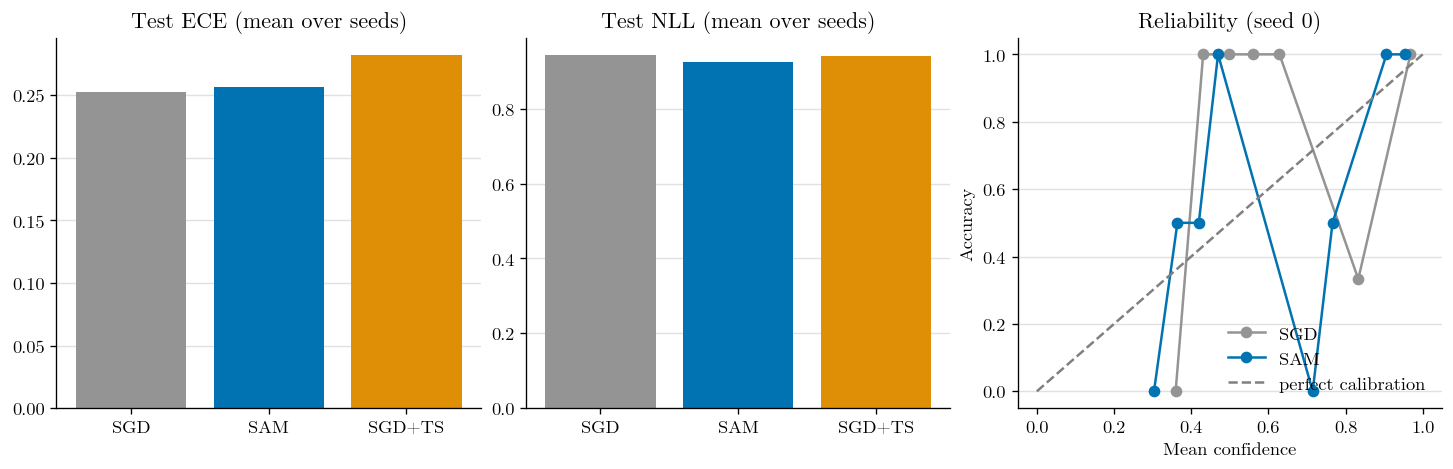

In [11]:
labels_m = ["SGD", "SAM", "SGD+TS"]
colours = [COLOURS["baseline"], COLOURS["method"], COLOURS["other_1"]]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, m in zip(axes[:2], ["ece", "nll"]):
    vals = [np.mean([r[k][m] for r in per_seed]) for k in labels_m]
    ax.bar(labels_m, vals, color=colours)
    ax.set_title(f"Test {m.upper()} (mean over seeds)")

# Reliability diagram on the first seed: accuracy against mean confidence per bin.
ax = axes[2]
first = per_seed[0]["logits"]
for name, key in (("SGD", "SGD"), ("SAM", "SAM")):
    conf, correct, _ = confidence_and_correct(first[key], test_y)
    rb = reliability_bins(conf, correct)
    keep = [i for i, c in enumerate(rb["count"]) if c > 0]
    ax.plot([rb["mean_confidence"][i] for i in keep], [rb["accuracy"][i] for i in keep],
            "o-", color=COLOURS["method"] if key == "SAM" else COLOURS["baseline"], label=name)
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.set_xlabel("Mean confidence")
ax.set_ylabel("Accuracy")
ax.set_title("Reliability (seed 0)")
ax.legend()
plt.show()


## Scaling and what the results show

**Scaling.** The first run used the smallest values (2 epochs, one seed), finished in about 70 seconds, and passed. The second run uses the original settings (40 epochs, seeds 0-4) and finishes in about a minute, well inside the 10-minute budget. The data subset is fixed at 100 images, so scaling the config further would not add information; the full-data run needs the original `method.py` with the torchvision download.

**Reading the printed table.** Each row is one test metric averaged over the five seeds. `SAM-SGD` is the paired difference per seed, with a 95% t-interval (df = 4) and Holm correction over the six metrics. On 20 test images, every interval includes zero and every Holm p-value is above 0.05, so this demo does not detect a difference between SAM and SGD. That is the expected outcome at this scale: a 20-image test set gives accuracy in steps of 0.05 and very wide intervals. It shows the pipeline runs, not the paper's effect.

**Reading the reliability plot.** The first seed's reliability curves sit near the diagonal only where the bins contain examples; with 20 test images most bins are empty or hold one or two points, so the curves are noisy. The temperature-scaled SGD row (`SGD+TS`) is the control the paper uses: one temperature is fitted on the validation logits, so its NLL can only match or improve on SGD on validation, not necessarily on test.

**Relation to the paper.** The paper's claim (SAM has lower ECE and NLL at 40 epochs on the full 10,000-image test set, and the NLL advantage survives temperature scaling) needs the full data. This notebook reproduces the procedure on the subset; the headline numbers in the paper are not reproduced here.
